# 현실의 데이터 07: 주가 지수: 내일 오를까?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/07_stock_index.ipynb)

**분야**: 금융 · 핀테크 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 시계열 예측 · 퀀트 · 투자 · 리스크 관리

> 코스피 10년치 매일 종가. 오늘까지의 움직임으로 내일 오를지 맞힐 수 있을까?

**데이터**: KOSPI 일별 지수 (^KS11) (약 0.3MB). Yahoo Finance 의 공개 차트 API 로 받은 코스피 지수 10년치 일별 시가 · 고가 · 저가 · 종가 · 거래량 (데이터 제공 조건은 Yahoo 이용 약관을 따른다).

산업 현장의 문제와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 거래일 하루 |
| ② 입력 X | 지난 5일의 수익률 (그날까지 알 수 있는 것만) |
| ③ 출력 y | 다음 거래일에 오르나 (분류) / 수익률 (회귀) |
| ④ 평가지표 | 정확도 · MAE |
| ⑤ 기준선 | 늘 '오른다' / 늘 0% |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Fama (1970) Efficient Capital Markets: A Review of Theory and Empirical Work, Journal of Finance](https://doi.org/10.2307/2325486)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

Yahoo Finance 의 공개 차트 주소에서 JSON 으로 받는다. 받기에 실패하면 잠시 뒤 다시 실행한다.

In [2]:
import json
URL = "https://query1.finance.yahoo.com/v8/finance/chart/%5EKS11?range=10y&interval=1d"
raw = json.load(open(download(URL, "data/yahoo_KS11.json")))["chart"]["result"][0]
q = raw["indicators"]["quote"][0]
df = pd.DataFrame({"date": pd.to_datetime(raw["timestamp"], unit="s").normalize(), "close": q["close"], "volume": q["volume"]}).dropna()
df = df.drop_duplicates("date").set_index("date")
print(df.shape, df.index.min().date(), "~", df.index.max().date())
df.sample(5, random_state=0).sort_index()

(2447, 2) 2016-10-17 ~ 2026-10-15


,close,volume
date,,
2019-02-18,2210.889893,314400
2020-03-23,1482.459961,647200
2020-07-02,2135.370117,1092000
2024-03-06,2641.489990,379000
2024-06-17,2744.100098,594000


## 열어 보기

종가와 **하루 수익률** (오늘 종가 ÷ 어제 종가 − 1). 수익률은 0 근처에서 위아래로 흔들린다.

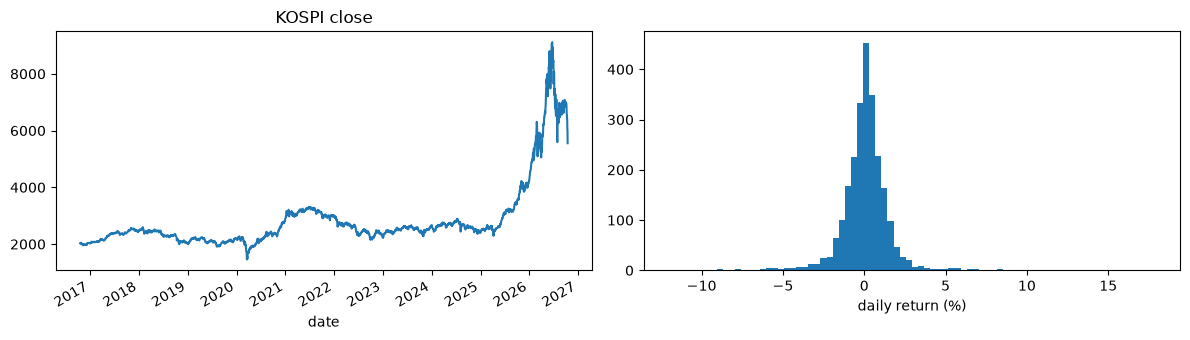

up days: 54.8%


In [3]:
df["ret"] = df["close"].pct_change()
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
df["close"].plot(ax=axs[0], title="KOSPI close")
axs[1].hist(df["ret"].dropna() * 100, bins=80); axs[1].set_xlabel("daily return (%)")
plt.tight_layout(); plt.show()
print(f"up days: {(df['ret'] > 0).mean():.1%}")

## 문제 하나 골라 보기: 지난 5일 → 내일 오를까

**시간 순서** 로 나눈다: 마지막 2년이 시험. 입력은 **그날까지 알 수 있는 것만** (내일 값을 쓰면 누수).
기준선: 늘 '오른다' (학습 기간에 오른 날이 더 많았다면).

In [4]:
from sklearn.linear_model import LogisticRegression

lags = pd.concat({f"ret_lag{k}": df["ret"].shift(k - 1) for k in range(1, 6)}, axis=1)      # lag1 = today's return
data = lags.assign(up_next=(df["ret"].shift(-1) > 0).astype(int), ret_next=df["ret"].shift(-1)).dropna()
cut = data.index.max() - pd.DateOffset(years=2)
tr, te = data[data.index <= cut], data[data.index > cut]
feats = list(lags.columns)

m = LogisticRegression().fit(tr[feats], tr["up_next"])
always_up = int(tr["up_next"].mean() > 0.5)
same_as_today = (te["ret_lag1"] > 0).astype(int)
for name, pred in [(f"always {'up' if always_up else 'down'}", np.full(len(te), always_up)), ("same as today", same_as_today),
                   ("logistic on 5 days", m.predict(te[feats]))]:
    print(f"{name:20s} accuracy {np.mean(pred == te['up_next']):.1%}")
print(f"regression baseline (predict 0%): MAE {np.mean(np.abs(te['ret_next'])) * 100:.2f}%p")

always up            accuracy 58.8%
same as today        accuracy 52.1%
logistic on 5 days   accuracy 58.8%
regression baseline (predict 0%): MAE 1.68%p


**관찰**: 지난 5일을 본 모델은 '늘 오른다' 기준선을 넘지 못한다 (모델이 사실상 늘 '오른다' 고 답한다). 그 기준선의 점수도 시험 기간 2년 동안 지수가 많이 올라서 높게 나온 것이라, 다른 기간이면 달라진다. 누구나 쓸 수 있는 과거 가격만으로는 내일을 맞히기 어렵다 (효율적 시장 가설). 기준선과 비교하지 않으면 '정확도 58%' 를 대단한 결과로 착각하기 쉽다.

## 다른 문제로 바꿔 보기

- **리스크 관리**: '오를까' 대신 '내일 얼마나 크게 흔들릴까 (변동성)' 는 꽤 잘 맞힌다. 큰 하루 뒤에는 큰 하루가 오기 쉽다.
- 다른 지수: `%5EIXIC` (나스닥 종합) 로 바꿔 보자. 결과가 비슷할까?
- **주의**: 시험 기간을 여러 번 바꿔 가며 가장 좋은 결과만 고르면, 그것도 미래를 엿본 셈이다.

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |